# Customer Analysis — Completed

This notebook implements customer analysis for the curated project. It measures **observed-window behavior**, not lifetime acquisition or churn. The population matches the established sales analysis: delivered orders with at least one recorded item. Merchandise revenue excludes freight, uses exact integer cents, and is aggregated to order grain before customer joins.

`customer_id` identifies an order-associated customer record; `customer_unique_id` identifies the repeat customer. Each order is counted once. No raw/cleaned inputs are changed and no individual customer identifiers are exported.


In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
while not (ROOT / 'src/analysis/eda.py').exists():
    if ROOT.parent == ROOT:
        raise RuntimeError('Run this notebook inside the project directory')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.analysis.customer_analytics import load_eligible, customer_analysis, cohort_analysis
OUT = ROOT / 'reports/completion_20261101/customer_analytics'
OUT.mkdir(parents=True, exist_ok=True)
eligible = load_eligible(ROOT)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.facecolor': 'white'})
print(f'Eligible delivered orders: {len(eligible):,}; customer IDs use customer_unique_id.')


Eligible delivered orders: 96,478; customer IDs use customer_unique_id.


## Customers, repeat behavior and revenue

Single-order and repeat customers are mutually exclusive over the full observed period. In monthly acquisition-style charts, “First observed month” includes all purchases in a customer's first eligible month; “Returning month” refers to later months. Neither proves a first-ever purchase outside the dataset. A customer making multiple purchases in one month contributes once to that month's customer count.


In [2]:
result = customer_analysis(eligible)
display(pd.Series(result['summary'], name='value').to_frame())
display(result['frequency'])
display(result['monthly'].tail(12))


,value
eligible_orders,96478
unique_customers,93358
single_order_customers,90557
repeat_customers,2801
repeat_customer_rate_pct,3.000278
orders_per_customer,1.03342
merchandise_revenue_cents,1322149811
snapshot_date,2018-08-30
first_eligible_purchase,2016-09-15 12:16:38
last_eligible_purchase,2018-08-29 15:00:37


,customers,revenue_cents
frequency,,
1,90557,1249308936
2,2573,63127490
3,181,6597442
4,28,1894673
5,9,561654
6,5,260066
7,3,228002
9,1,100085
15,1,71463


customer_type,First observed month,Returning month
month,,
2017-09,4004,79
2017-10,4328,89
2017-11,7060,123
2017-12,5338,112
2018-01,6842,132
2018-02,6288,112
2018-03,6774,140
2018-04,6582,162
2018-05,6506,187


## RFM segmentation

The reference date is the day after the latest eligible purchase, anchored to this historical dataset. Recency is calendar days since the last eligible purchase. Frequency is the number of distinct eligible orders. Monetary value is the sum of merchandise cents.

R and M use average percentile ranks mapped to scores 1–5; all tied values receive the same score. More recent and higher-value customers score higher. F uses explicit order counts (1, 2, 3, 4, 5+), because a large tied one-order population makes five equal-sized frequency groups misleading. The six segments combine recent (R≥4), repeat (F≥2), and high monetary value (M≥4) as documented in the module. These are descriptive prioritization rules, not validated response or churn predictions.


,customers,orders,revenue_cents,median_recency_days,customer_share_pct,revenue_share_pct
segment,,,,,,
Earlier single,54439,54439,742610328,313.0,58.312089,56.166882
Recent single,21715,21715,120930046,91.0,23.259924,9.146471
Recent high-value single,14403,14403,385768562,94.0,15.427708,29.177371
Earlier repeat,1600,3335,40325100,294.0,1.713833,3.049965
Recent high-value repeat,931,2038,30512229,88.0,0.997236,2.307774
Recent repeat,270,548,2003546,90.0,0.289209,0.151537


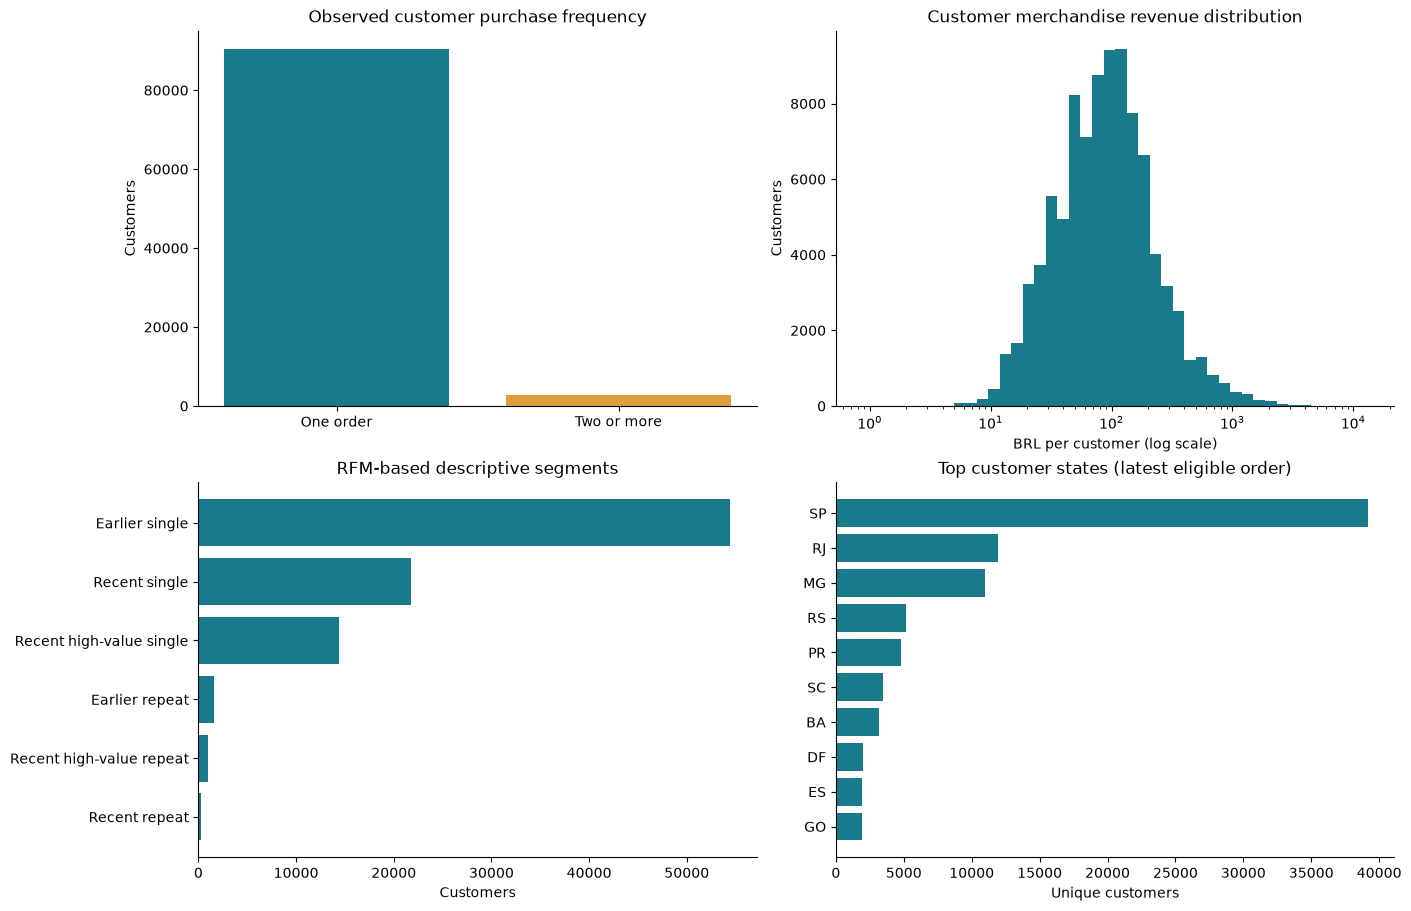

In [3]:
display(result['segments'].sort_values('customers', ascending=False))
fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
customers = result['customers']
axes[0,0].bar(['One order', 'Two or more'], [int(customers.frequency.eq(1).sum()), int(customers.frequency.ge(2).sum())], color=['#197A8C','#E09F3E'])
axes[0,0].set(title='Observed customer purchase frequency', ylabel='Customers')
revenue = customers.monetary_cents.astype(float) / 100
axes[0,1].hist(revenue, bins=np.geomspace(max(revenue.min(), .01), revenue.max(), 45), color='#197A8C')
axes[0,1].set_xscale('log')
axes[0,1].set(title='Customer merchandise revenue distribution', xlabel='BRL per customer (log scale)', ylabel='Customers')
segments = result['segments'].sort_values('customers')
axes[1,0].barh(segments.index, segments.customers, color='#197A8C')
axes[1,0].set(title='RFM-based descriptive segments', xlabel='Customers')
geo = result['geography'].nlargest(10, 'customers').sort_values('customers')
axes[1,1].barh(geo.index, geo.customers, color='#197A8C')
axes[1,1].set(title='Top customer states (latest eligible order)', xlabel='Unique customers')
fig.savefig(OUT / 'customer_profile.png', dpi=160)
plt.show()


## Customer geography

For a mutually exclusive customer geographic split, each customer is assigned to their latest eligible order's state; order ID breaks timestamp ties deterministically. Revenue in this table is all eligible lifetime-in-window revenue for customers assigned to that state. It differs deliberately from order-location revenue and should not replace the Power BI order-state sales measure.


,customers,repeat_customers,revenue_cents,repeat_customer_rate_pct
latest_customer_state,,,,
SP,39150,1224,506954764,3.126437
RJ,11914,391,175951194,3.281853
MG,10995,321,155224281,2.919509
RS,5167,158,72897747,3.057867
PR,4766,139,66510864,2.916492
SC,3446,94,50671013,2.727800
BA,3156,88,49335415,2.788340
DF,2016,58,29569771,2.876984
ES,1928,57,26873335,2.956432


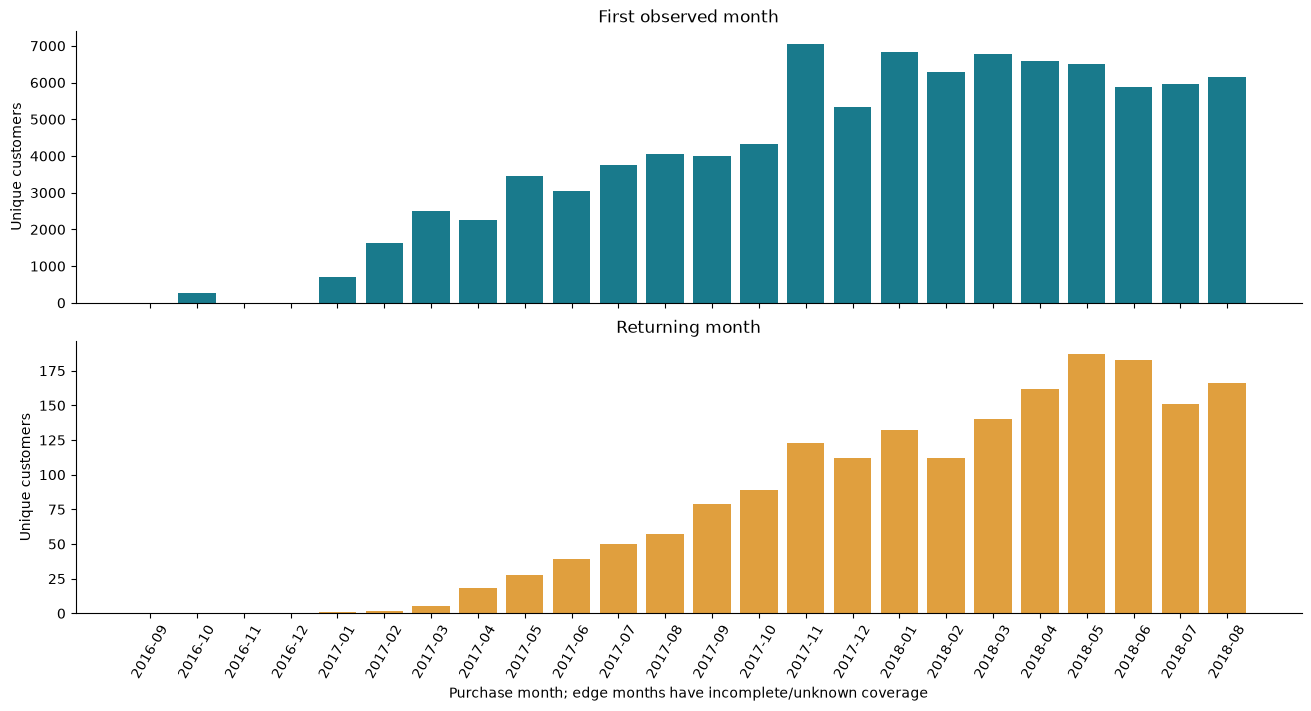

In [4]:
display(result['geography'].sort_values('customers', ascending=False))
monthly = result['monthly'].copy()
monthly.index = monthly.index.astype(str)
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, constrained_layout=True)
for ax, name, color in zip(axes, ['First observed month', 'Returning month'], ['#197A8C', '#E09F3E']):
    ax.bar(monthly.index, monthly[name], color=color)
    ax.set(title=name, ylabel='Unique customers')
axes[1].tick_params(axis='x', rotation=60)
axes[1].set_xlabel('Purchase month; edge months have incomplete/unknown coverage')
fig.savefig(OUT / 'customer_monthly_activity.png', dpi=160)
plt.show()


In [5]:
s = result['summary']
display(Markdown(f"**Interpretation:** {s['repeat_customers']:,} of {s['unique_customers']:,} observed customers made at least two eligible orders ({s['repeat_customer_rate_pct']:.2f}%). Mean orders per customer are {s['orders_per_customer']:.3f}. The top 10% of customers by observed merchandise revenue account for {s['top_decile_revenue_share_pct']:.2f}% of revenue. This suggests testing repeat-purchase propositions and prioritizing service for high-value customers, but does not establish causality, profit, churn or customer lifetime value."))
assert result['customers'].index.is_unique
assert result['customers'].frequency.sum() == len(eligible)
assert result['customers'].monetary_cents.sum() == eligible.merchandise_revenue_cents.sum()
print('PASS: identity, order-count and exact-cent reconciliation assertions.')


**Interpretation:** 2,801 of 93,358 observed customers made at least two eligible orders (3.00%). Mean orders per customer are 1.033. The top 10% of customers by observed merchandise revenue account for 41.10% of revenue. This suggests testing repeat-purchase propositions and prioritizing service for high-value customers, but does not establish causality, profit, churn or customer lifetime value.

PASS: identity, order-count and exact-cent reconciliation assertions.
